# 05 · Laya vs LLM-only routing: latency and cost

Notebook 04 put fine-tuned Laya in the router node of a LangGraph workflow. The common alternative is to let an
**LLM make that decision** too. This notebook compares the two on the same graph and the same tickets:

| router | how it decides |
|---|---|
| **Laya (fine-tuned)** | our fine-tuned Laya from notebook 02: one encoder forward pass, typed answers |
| **Gemini only** | Gemini with structured JSON output, a written routing policy and 12 labelled examples |
| **Hybrid Laya→Gemini** | Laya answers; only tickets where Laya is unsure go to Gemini |
| XGBoost (optional) | grey reference line: the cheapest strong baseline from notebook 03 |

For each router we measure:
- **quality**: correct destination (the node the ticket lands in) and exact match (all three fields right)
- **latency**: router-node p50 / p95 and whole-graph p50 / p95
- **cost**: tokens per call and **$ per 1,000 tickets**, plus how often the LLM's answer was unusable

The specialist agents stay stubs, so the only thing that changes between runs is the routing decision.

**Runtime:** GPU (Runtime → Change runtime type → T4). **Needs:** the fine-tuned Laya checkpoint saved to Drive in
notebook 02, and a Gemini API key (from https://aistudio.google.com/apikey).

## Setup

Works both on **Colab** and locally. On Colab this clones the repo and moves into it;
locally (opened from `notebooks/`) it just moves up to the repo root so `import src...` works.

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/AdityaThakare72/typed-decision-models.git"
BRANCH = "main"

if not os.path.exists("src/dataset.py"):
    if os.path.exists("../src/dataset.py"):      # running locally from notebooks/
        os.chdir("..")
    else:                                         # fresh Colab runtime
        if not os.path.exists("typed-decision-models"):
            subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL], check=True)
        os.chdir("typed-decision-models")
sys.path.insert(0, os.getcwd())
print("working dir:", os.getcwd())

working dir: /content/typed-decision-models


Install Laya, the Gemini SDK (`google-genai`) and LangGraph. `USE_TF=0` stops `transformers` from probing
TensorFlow, which can hang Laya loading on Colab.

In [2]:
%pip install -q laya google-genai langgraph scikit-learn xgboost pandas matplotlib
os.environ["USE_TF"] = "0"

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.2/121.2 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 436.6/436.6 kB 11.2 MB/s eta 0:00:00
device: cuda


## 1. API key

On Colab, add the key once under the **🔑 Secrets** tab (left sidebar) with the name `GEMINI_API_KEY` and allow
notebook access. Otherwise you'll be prompted for it. The key is never printed or saved in the notebook.

In [3]:
try:
    from google.colab import userdata
    os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
except Exception:
    if not os.environ.get("GEMINI_API_KEY"):
        from getpass import getpass
        os.environ["GEMINI_API_KEY"] = getpass("Gemini API key: ")
print("key loaded:", bool(os.environ.get("GEMINI_API_KEY")))

key loaded: True


## 2. Settings

- `LAYA_DIR`: where notebook 02 saved the fine-tuned checkpoint (`LOAD_FROM_DRIVE = True` mounts Drive first).
- `GEMINI_MODEL`: `gemini-3.1-flash-lite` is the cheapest current 3-series model ($0.25 in / $1.50 out per 1M tokens).
  Try `gemini-3.8-flash` for a stronger (pricier) LLM. Prices live in `GEMINI_PRICES_PER_1M` in `src/models/llm_router.py`
  (checked 2026-10-19 on the official pricing page; check again before quoting numbers).
- `N_TICKETS`: how many test tickets go through every router. 100 keeps the run around 10–15 minutes on a free key.
- `FREE_TIER`: pauses ~6 s between Gemini calls to stay under free-tier rate limits. The pause is **not** counted in
  latency. Set `False` with a paid key. (Free-tier prompts may be used by Google to improve its products; our tickets are synthetic.)
- `HYBRID_THRESHOLD`: escalate to Gemini when Laya's **least confident field** is below this. Section 4 helps pick it.
- `INCLUDE_XGBOOST`: add XGBoost as a grey reference (trains in seconds on CPU).
- `CPU_USD_PER_HOUR` / `GPU_USD_PER_HOUR`: rough cloud prices to turn local inference time into dollars.

In [4]:
LOAD_FROM_DRIVE = True
LAYA_DIR = "/content/drive/MyDrive/typed-decision-models/laya-finetuned"   # or "artifacts/laya-finetuned"

GEMINI_MODEL = "gemini-3.1-flash-lite"
N_TICKETS = 100
FREE_TIER = True
HYBRID_THRESHOLD = 0.8
INCLUDE_XGBOOST = True

# Assumed on-demand prices for a small CPU VM and a T4 GPU VM. Edit to match your cloud.
CPU_USD_PER_HOUR = 0.04
GPU_USD_PER_HOUR = 0.35

PAUSE_S = 6.0 if FREE_TIER else 0.0

## 3. Data and fine-tuned Laya

Same splits as every other notebook. The ticket sample is fixed (seed 42), so every router sees exactly the same tickets.

In [5]:
from src.dataset import load_splits
from src.models.laya_model import LayaDecisionModel

train_df, val_df, test_df = load_splits("data")
sample = test_df.sample(n=min(N_TICKETS, len(test_df)), random_state=42).reset_index(drop=True)

if LOAD_FROM_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
laya = LayaDecisionModel(LAYA_DIR, name="laya:finetuned", device=DEVICE).load()

xgb = None
if INCLUDE_XGBOOST:
    from src.models.classical_ml import ClassicalDecisionModel
    xgb = ClassicalDecisionModel("xgb").fit(train_df)
print(f"{len(sample)} tickets | decision models:", [m.name for m in [laya, xgb] if m is not None])

Mounted at /content/drive
100 tickets | decision models: ['laya:finetuned', 'xgboost']


## 4. When is Laya unsure? Picking the hybrid threshold

The hybrid sends a ticket to Gemini when Laya's **least confident field** (route, priority or requires-human) is below
the threshold. Route confidence alone hides most mistakes, because they're mostly in priority.

On the **validation** split (not the test tickets), for each threshold: how many tickets would go to Gemini, and how
often Laya is fully right on those vs the rest. A good threshold catches a small share of tickets where Laya is often
wrong. Fine-tuning refit Laya's calibration, so these confidences are meaningful (see notebook 02).

In [6]:
import numpy as np
import pandas as pd
from src.dataset import LABEL_COLUMNS
from src.interface import outputs_to_frame

val_out = laya.predict_batch(val_df)
val_conf = np.array([o.min_confidence() for o in val_out])
val_right = (outputs_to_frame(val_out).astype(str).values == val_df[LABEL_COLUMNS].astype(str).values).all(axis=1)

rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    unsure = val_conf < t
    rows.append({"threshold": t, "share_to_gemini": unsure.mean(),
                 "laya_exact_on_unsure": val_right[unsure].mean() if unsure.any() else np.nan,
                 "laya_exact_on_rest": val_right[~unsure].mean()})
pd.DataFrame(rows).set_index("threshold").round(3)

,share_to_gemini,laya_exact_on_unsure,laya_exact_on_rest
threshold,,,
0.5,0.011,0.400,0.756
0.6,0.064,0.655,0.758
0.7,0.131,0.576,0.778
0.8,0.224,0.584,0.800
0.9,0.499,0.671,0.832


## 5. The Gemini router

`GeminiDecisionModel` (in `src/models/llm_router.py`) sends a **system prompt** (team descriptions, the routing policy in
plain words, 12 labelled examples, two per team) plus the ticket as JSON. Gemini must reply with JSON that matches a
schema (enums for the team and priority), so there's no free-text parsing. Thinking is set to `minimal`: a router doesn't
need long reasoning, and thinking tokens are billed as output.

A fair setup: Gemini gets what a human agent would get on day one (the policy and some examples), while Laya was
fine-tuned on the 2,099 training tickets. Here's the start of the prompt:

In [7]:
from src.models.llm_router import GeminiDecisionModel, pick_examples

examples = pick_examples(train_df, per_route=2)


def new_gemini():
    """A fresh Gemini router, so each experiment tracks its own calls and cost."""
    return GeminiDecisionModel(GEMINI_MODEL, examples=examples, min_seconds_between_calls=PAUSE_S)


gemini = new_gemini()
print(gemini.system_prompt[:1500], "...")
print(f"\nsystem prompt: {len(gemini.system_prompt):,} characters")

You are the router for a customer-support system. For each ticket decide:

1. route_target: which team handles it.
   - billing: payments, charges, refunds, invoices, subscriptions
   - orders: placing, changing, tracking or cancelling orders and deliveries
   - account: login details, profile changes, creating or deleting an account
   - tech_support: bugs, errors, crashes, outages, the app or site not working
   - fraud: unauthorised charges, hacked accounts, scams, suspicious activity
   - general: feedback, general questions, anything else

2. priority_level: low, medium, high or critical. Weigh these together:
   - urgency_score (0 to 1): higher means more urgent
   - account_tier: enterprise counts most, then pro, then free
   - past_failures: each earlier failed attempt makes it more urgent
   - fraud tickets are more urgent, tech_support tickets slightly more urgent
   Most tickets are medium. Critical is rare: only the most urgent combinations.

3. requires_human: true if ANY 

One test call, to see the decision and what it cost.

In [8]:
probe = new_gemini()
answer = probe.predict_one(sample.iloc[0])
print("ticket :", sample.iloc[0]["query"])
print("gemini :", answer.route, answer.priority, "human =", answer.requires_human, f"({answer.latency_ms:.0f} ms)")
print("truth  :", sample.iloc[0]["route_target"], sample.iloc[0]["priority_level"], "human =", sample.iloc[0]["requires_human"])
probe.calls[0]

ticket : how long does shipping take to Pune thanks
gemini : orders medium human = False (3264 ms)
truth  : orders low human = False


{'latency_ms': 3263.859769000021,
 'input_tokens': 1326,
 'output_tokens': 32,
 'cost_usd': 0.0003795,
 'ok': True}

## 6. The routers

`HybridDecisionModel` (in `src/models/hybrid.py`) runs Laya first and calls Gemini only when Laya's weakest field
confidence is below `HYBRID_THRESHOLD`. Each Gemini-backed router gets its own Gemini instance so its cost is counted
separately.

In [9]:
from src.models.hybrid import HybridDecisionModel

routers = {
    "Laya (fine-tuned)": laya,
    "Gemini only": gemini,
    "Hybrid Laya→Gemini": HybridDecisionModel(laya, new_gemini(), threshold=HYBRID_THRESHOLD),
}
if xgb is not None:
    routers["XGBoost (reference)"] = xgb
list(routers)

['Laya (fine-tuned)',
 'Gemini only',
 'Hybrid Laya→Gemini',
 'XGBoost (reference)']

## 7. Run every router through the same graph

`build_router_graph` (in `src/router_graph.py`) is the graph from notebook 04 with the router model plugged in; `run_tickets`
sends each ticket through it once and records where it landed and how long the router and the whole graph took.
With `FREE_TIER = True` the Gemini runs take a while because of the pauses between calls.

In [10]:
import time
from src.router_graph import build_router_graph, run_tickets

runs = {}
for label, model in routers.items():
    start = time.time()
    graph = build_router_graph(model, confidence_floor=0.5)
    runs[label] = run_tickets(graph, sample)
    print(f"{label:<22} done in {time.time() - start:6.1f} s wall-clock")

Laya (fine-tuned)      done in    6.5 s wall-clock
Gemini only            done in  595.2 s wall-clock
Hybrid Laya→Gemini     done in  139.2 s wall-clock
XGBoost (reference)    done in    1.9 s wall-clock


## 8. Results table

- **Cost per 1k tickets** = Gemini tokens × price, plus local compute time × the hourly price above (that part is an
  upper bound: it assumes the machine does nothing else). Laya needs a GPU machine; Gemini runs on Google's.
- **LLM share** = fraction of tickets that called Gemini.
- **Failed answers** = Gemini replies that didn't match the schema (those tickets go to a human).

In [11]:
ON_GPU = {"Laya (fine-tuned)", "Hybrid Laya→Gemini"}
# Which decision model runs locally inside each router (the hybrid runs Laya on every ticket).
LOCAL_PART = {"Laya (fine-tuned)": "Laya (fine-tuned)", "Hybrid Laya→Gemini": "Laya (fine-tuned)",
              "XGBoost (reference)": "XGBoost (reference)"}


def llm_part(model):
    """The Gemini instance inside a router (or None) and the share of tickets it handled."""
    if isinstance(model, GeminiDecisionModel):
        return model, 1.0
    if isinstance(model, HybridDecisionModel):
        return model.slow, model.escalation_rate()
    return None, 0.0


rows = []
for label, res in runs.items():
    model = routers[label]
    llm, llm_share = llm_part(model)
    hourly = GPU_USD_PER_HOUR if label in ON_GPU else CPU_USD_PER_HOUR
    # Local compute: the decision model's own time per ticket, at the machine's hourly price.
    local_ms = runs[LOCAL_PART[label]]["router_ms"].mean() if label in LOCAL_PART else 0.0
    local_cost_1k = local_ms / 1000 / 3600 * hourly * 1000
    usage = llm.usage_summary() if llm is not None else {}
    llm_cost_1k = usage.get("total_cost_usd", 0.0) / len(res) * 1000
    rows.append({
        "router": label,
        "correct_destination": res["correct_destination"].mean(),
        "exact_match": res["exact"].mean(),
        "router_p50_ms": np.percentile(res["router_ms"], 50),
        "router_p95_ms": np.percentile(res["router_ms"], 95),
        "graph_p50_ms": np.percentile(res["graph_ms"], 50),
        "graph_p95_ms": np.percentile(res["graph_ms"], 95),
        "llm_share": llm_share,
        "avg_input_tokens": usage.get("avg_input_tokens", 0.0),
        "avg_output_tokens": usage.get("avg_output_tokens", 0.0),
        "failed_answers": usage.get("failed_parses", 0),
        "usd_per_1k_tickets": llm_cost_1k + local_cost_1k,
    })

summary = pd.DataFrame(rows).set_index("router")
os.makedirs("artifacts", exist_ok=True)
summary.to_csv("artifacts/results_laya_vs_llm.csv")
summary.round(4)

,correct_destination,exact_match,router_p50_ms,router_p95_ms,graph_p50_ms,graph_p95_ms,llm_share,avg_input_tokens,avg_output_tokens,failed_answers,usd_per_1k_tickets
router,,,,,,,,,,,
Laya (fine-tuned),0.90,0.76,45.4362,65.7776,47.9779,70.6274,0.00,0.00,0.000,0,0.0046
Gemini only,0.88,0.51,971.7589,1438.2610,973.9805,1440.2680,1.00,1329.39,32.460,0,0.3810
Hybrid Laya→Gemini,0.89,0.71,68.4652,1147.6640,70.9219,1151.1544,0.24,1329.75,32.375,0,0.0961
XGBoost (reference),0.89,0.72,16.7651,20.9069,18.6927,23.0723,0.00,0.00,0.000,0,0.0002


## 9. Charts

Same colour per router in every chart: Laya green (as in notebook 03), Gemini violet, hybrid magenta, XGBoost as a
grey reference. Latency and cost use **log scales**, because the routers differ by orders of magnitude.

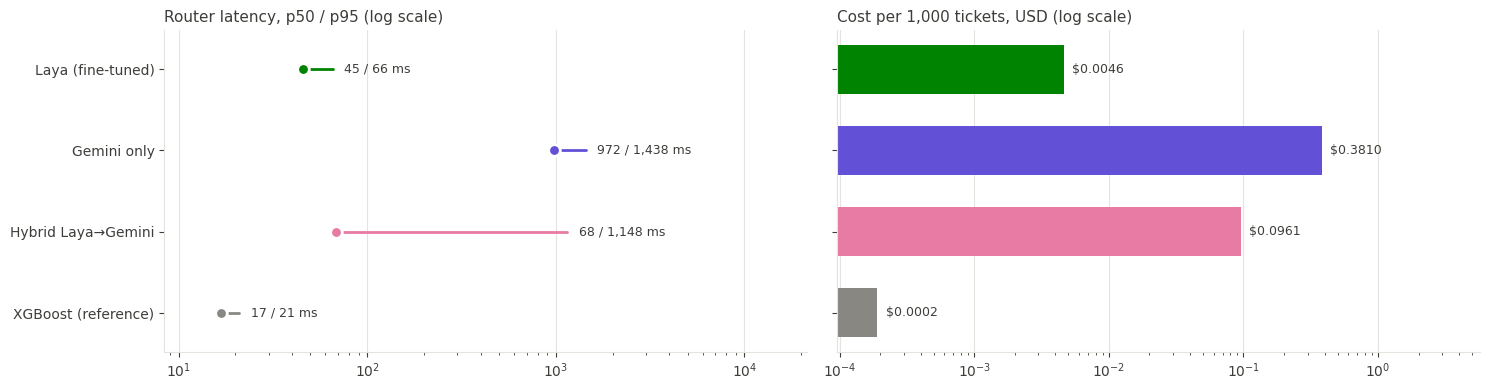

In [12]:
import matplotlib.pyplot as plt

# Validated together (all pairs, incl. colour-blind simulation); XGBoost is muted grey as a reference.
ROUTER_COLORS = {
    "Laya (fine-tuned)": "#008300",
    "Gemini only": "#6250d6",
    "Hybrid Laya→Gemini": "#e87ba4",
    "XGBoost (reference)": "#898781",
}
TEXT_COLOR, GRID_COLOR = "#3d3d3a", "#e4e3dd"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID_COLOR, "axes.labelcolor": TEXT_COLOR,
                     "xtick.color": TEXT_COLOR, "ytick.color": TEXT_COLOR, "axes.titlecolor": TEXT_COLOR})
order = list(summary.index)


def tidy(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)


fig, (left, right) = plt.subplots(1, 2, figsize=(15, 0.6 * len(order) + 1.6), sharey=True)

# Left: router latency, dot = p50, line end = p95
for y, label in enumerate(order):
    p50, p95 = summary.loc[label, "router_p50_ms"], summary.loc[label, "router_p95_ms"]
    color = ROUTER_COLORS.get(label, "#898781")
    left.plot([p50, p95], [y, y], color=color, linewidth=2, solid_capstyle="round")
    left.scatter([p50], [y], s=70, color=color, edgecolor="white", linewidth=2, zorder=3)
    left.text(p95 * 1.15, y, f"{p50:,.0f} / {p95:,.0f} ms", va="center", fontsize=9, color=TEXT_COLOR)
left.set_yticks(range(len(order)), order)
left.set_xscale("log")
left.set_xlim(summary["router_p50_ms"].min() / 2, summary["router_p95_ms"].max() * 15)
left.set_title("Router latency, p50 / p95 (log scale)", loc="left", fontsize=11)
tidy(left)

# Right: dollars per 1,000 tickets
costs = summary["usd_per_1k_tickets"].values
right.barh(order, costs, color=[ROUTER_COLORS.get(l, "#898781") for l in order], height=0.6)
for y, v in enumerate(costs):
    right.text(v * 1.15, y, f"${v:.4f}", va="center", fontsize=9, color=TEXT_COLOR)
right.set_xscale("log")
right.set_xlim(costs.min() / 2, costs.max() * 15)
right.set_title("Cost per 1,000 tickets, USD (log scale)", loc="left", fontsize=11)
tidy(right)

left.invert_yaxis()
fig.tight_layout()
plt.show()

Quality vs cost: upper-left is best (more right answers for less money).

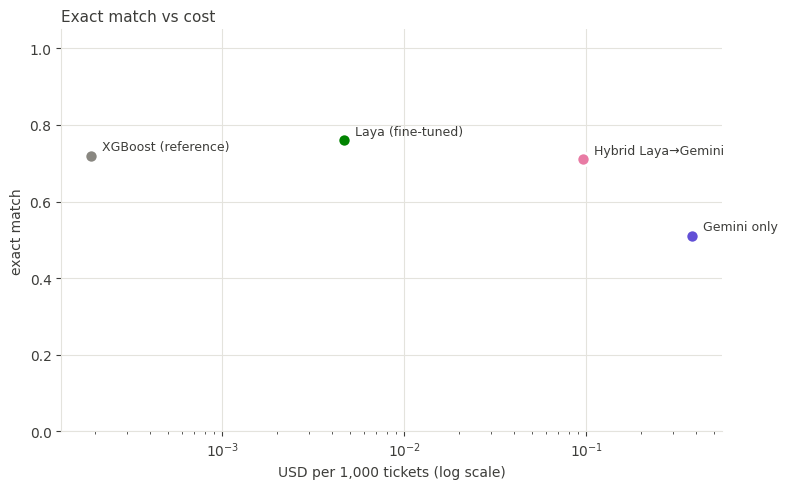

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for label in order:
    x, y = summary.loc[label, "usd_per_1k_tickets"], summary.loc[label, "exact_match"]
    ax.scatter([x], [y], s=90, color=ROUTER_COLORS.get(label, "#898781"), edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(label, (x, y), xytext=(8, 4), textcoords="offset points", fontsize=9, color=TEXT_COLOR)
ax.set_xscale("log")
ax.set_xlabel("USD per 1,000 tickets (log scale)")
ax.set_ylabel("exact match")
ax.set_ylim(0, 1.05)
ax.set_title("Exact match vs cost", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 10. What does it look like at scale?

Projected monthly cost and the time spent waiting on the router, at 1 million tickets a month. Latency adds up as
user-facing wait time even when money doesn't.

In [14]:
TICKETS_PER_MONTH = 1_000_000

projection = pd.DataFrame({
    "usd_per_month": summary["usd_per_1k_tickets"] * TICKETS_PER_MONTH / 1000,
    "router_hours_per_month": summary["router_p50_ms"] * TICKETS_PER_MONTH / 1000 / 3600,
    "wrong_destinations_per_month": (1 - summary["correct_destination"]) * TICKETS_PER_MONTH,
})
projection.round(0).astype(int)

,usd_per_month,router_hours_per_month,wrong_destinations_per_month
router,,,
Laya (fine-tuned),5,13,100000
Gemini only,381,270,120000
Hybrid Laya→Gemini,96,19,110000
XGBoost (reference),0,5,110000


## 11. Where do Laya and Gemini disagree?

Tickets where exactly one of them picked the right destination. This shows what kind of mistakes each one makes:
Gemini reads language well but has to guess the numeric policy from words; Laya learned it from data.

In [15]:
both = sample[["query", "account_tier", "urgency_score", "past_failures", "route_target", "priority_level", "requires_human"]].copy()
both["laya_dest"] = runs["Laya (fine-tuned)"]["handled_by"]
both["gemini_dest"] = runs["Gemini only"]["handled_by"]
both["should_be"] = runs["Laya (fine-tuned)"]["expected"]
laya_only = both[(both["laya_dest"] == both["should_be"]) & (both["gemini_dest"] != both["should_be"])]
gemini_only = both[(both["gemini_dest"] == both["should_be"]) & (both["laya_dest"] != both["should_be"])]
print(f"Laya right, Gemini wrong: {len(laya_only)} | Gemini right, Laya wrong: {len(gemini_only)}")
pd.concat([laya_only.head(5), gemini_only.head(5)])

Laya right, Gemini wrong: 3 | Gemini right, Laya wrong: 1


,query,account_tier,urgency_score,past_failures,route_target,priority_level,requires_human,laya_dest,gemini_dest,should_be
24,can I suggest a feature for notifications,enterprise,0.516,2,general,high,True,human_handoff,general_agent,human_handoff
50,do you have a student discount asap,free,0.529,0,general,low,False,general_agent,billing_agent,general_agent
59,the app keeps crashing when I open notificatio...,enterprise,0.275,2,tech_support,high,True,human_handoff,tech_support_agent,human_handoff
58,why did my card get declined when paying for b...,enterprise,0.366,0,billing,medium,False,human_handoff,billing_agent,billing_agent


Priority is where they differ most. Priority confusion tables for both (rows = true level):

In [16]:
priority_order = ["low", "medium", "high", "critical"]
for label in ["Laya (fine-tuned)", "Gemini only"]:
    print(label)
    print(pd.crosstab(sample["priority_level"], runs[label]["priority"], rownames=["true"], colnames=["predicted"])
          .reindex(index=priority_order, columns=priority_order, fill_value=0), "\n")

Laya (fine-tuned)
predicted  low  medium  high  critical
true                                  
low         24       0     1         0
medium       3      47     2         0
high         0       8    11         0
critical     0       0     2         2 

Gemini only
predicted  low  medium  high  critical
true                                  
low         16       9     0         0
medium       7      30    15         0
high         0       8    10         1
critical     0       0     3         1 



**Takeaways (Colab T4 + free Gemini key, 100 tickets):**
- **Exact match:** Laya 0.76 vs Gemini only 0.51 vs hybrid 0.71 (XGBoost reference 0.72). With 100 tickets the margin
  is about ±0.05, so Laya vs Gemini is a real gap; Laya vs XGBoost is a tie.
- **Why:** correct destination is close for all (0.88–0.90), because route and human hand-off are easy to read from
  text. The gap is priority: Gemini gets 57 of 100 right vs 84 for Laya, smearing medium tickets into low and high.
  A numeric policy written in words is hard to apply; Laya learned it from data.
- **Router p50 / p95 latency:** Laya 45 / 66 ms (T4) vs Gemini 972 / 1,438 ms, about **21x slower** at the median.
  At 1M tickets a month that's ~270 hours of waiting on the router vs ~13.
- **Cost per 1M tickets:** Laya ~$5 (T4 time) vs Gemini $381 vs hybrid $96. Each Gemini call is ~1,330 input +
  32 output tokens; no answer broke the JSON schema.
- **The hybrid did not pay off:** it sent 24% of tickets to Gemini and lost 5 points (0.76 → 0.71), because Gemini is
  weaker than Laya even on the tickets Laya is unsure about. Escalation only helps when the fallback is stronger
  (a bigger LLM, or a human).

Caveat: Gemini latency includes the network round trip from Colab, and API latency varies by time of day.